<a href="https://colab.research.google.com/github/Rajapaksha-RMDD/pusl3123-ai-ml-coursework/blob/main/Exercise_2_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Use the exact same preprocessing as Exercise 1
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False, num_workers=2)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Dataset loaded. Running on: {device}")

100%|██████████| 170M/170M [32:03<00:00, 88.6kB/s]


Dataset loaded. Running on: cuda:0


CNN Total Trainable Parameters: 25,578
----------------------------------------
Starting CNN Training...
Epoch [1/15] | Train Loss: 1.4660 | Train Acc: 48.08% | Val Loss: 1.2630 | Val Acc: 55.03%
Epoch [2/15] | Train Loss: 1.1542 | Train Acc: 59.62% | Val Loss: 1.0818 | Val Acc: 62.25%
Epoch [3/15] | Train Loss: 1.0303 | Train Acc: 64.35% | Val Loss: 1.0333 | Val Acc: 63.69%
Epoch [4/15] | Train Loss: 0.9550 | Train Acc: 67.00% | Val Loss: 0.9725 | Val Acc: 66.31%
Epoch [5/15] | Train Loss: 0.8997 | Train Acc: 68.78% | Val Loss: 0.9440 | Val Acc: 67.45%
Epoch [6/15] | Train Loss: 0.8591 | Train Acc: 70.27% | Val Loss: 0.9259 | Val Acc: 68.27%
Epoch [7/15] | Train Loss: 0.8240 | Train Acc: 71.63% | Val Loss: 0.9303 | Val Acc: 68.03%
Epoch [8/15] | Train Loss: 0.7959 | Train Acc: 72.51% | Val Loss: 0.9076 | Val Acc: 68.84%
Epoch [9/15] | Train Loss: 0.7719 | Train Acc: 73.18% | Val Loss: 0.9059 | Val Acc: 69.33%
Epoch [10/15] | Train Loss: 0.7486 | Train Acc: 74.02% | Val Loss: 0.9174 | 

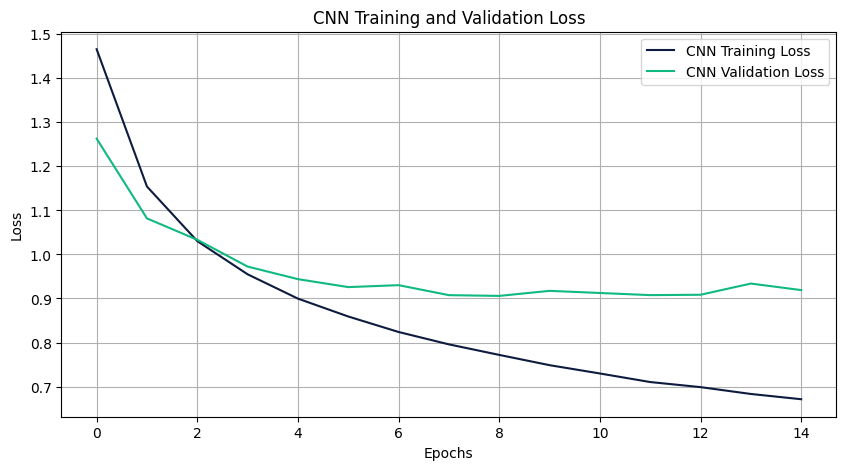

In [2]:
# 1. Define the CNN Architecture (3 Trainable Layers)
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        # Trainable Layer 1: Convolutional Layer
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
        # Trainable Layer 2: Convolutional Layer
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        # Pooling layer (Not trainable)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        # Trainable Layer 3: Fully Connected Layer
        # 32x32 image pooled twice becomes 8x8 -> 32 channels * 8 * 8 = 2048
        self.fc1 = nn.Linear(32 * 8 * 8, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 32 * 8 * 8)
        x = self.fc1(x)
        return x

# 2. Initialize Model, Loss, and Optimizer
cnn_model = CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

# Count trainable parameters for your report comparison
cnn_params = sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)
print(f"CNN Total Trainable Parameters: {cnn_params:,}")
print("-" * 40)

# 3. Training and Evaluation Loop
epochs = 15
cnn_train_losses, cnn_val_losses = [], []
cnn_train_accuracies, cnn_val_accuracies = [], []

print("Starting CNN Training...")
for epoch in range(epochs):
    # Training Phase
    cnn_model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = cnn_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / len(trainloader)
    epoch_train_acc = 100 * correct_train / total_train
    cnn_train_losses.append(epoch_train_loss)
    cnn_train_accuracies.append(epoch_train_acc)

    # Validation Phase
    cnn_model.eval()
    val_loss, correct_val, total_val = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = cnn_model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    epoch_val_loss = val_loss / len(testloader)
    epoch_val_acc = 100 * correct_val / total_val
    cnn_val_losses.append(epoch_val_loss)
    cnn_val_accuracies.append(epoch_val_acc)

    print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% | Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.2f}%")

print("CNN Training Complete!")

# 4. Plot Training and Validation Loss
plt.figure(figsize=(10, 5))
plt.plot(cnn_train_losses, label='CNN Training Loss', color='#0D1B3E')
plt.plot(cnn_val_losses, label='CNN Validation Loss', color='#10b981')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('CNN Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()